# 2. Erronka – Smart Environment AI: Sare neuronala (MIA)

**Modulua:** Adimen Artifizialaren ereduak · **Zikloa:** IA eta Big Data (FP Santurtzi)

## 1. Sarrera

Cuaderno honetan **MLP sare neuronal sinple bat** eraikiko dugu TensorFlow/Keras erabiliz, **PM10**-en kontzentrazioa kalkulatzeko. Emaitzak eredu klasikoekin konparatu ahal izateko, SAA zatiko **datu, ezaugarri eta banaketa berberak** erabiltzen ditugu.

Hauek egingo ditugu:

1. Datuak kargatu eta SAAko banaketa kronologikoa errepikatu.
2. Erreferentziak prestatu: batezbestekoa eta SAAn aukeratutako Ridge eredua.
3. MLP-a eraiki eta hiperparametroak balidazioarekin doitu.
4. MLP-a *test* multzoan ebaluatu eta eredu klasikoarekin konparatu.
5. Eredurik onena aukeratu eta Jetson Nano-rako esportatu.

## 2. Datuen prestaketa

SAAn bezala: `O3 8h` zutabea kentzen dugu, PM10 hutsik duten errenkadak kentzen ditugu, eta lehen %80 entrenatzeko eta azken %20 probatzeko erabiltzen dugu, ordena kronologikoan.

In [1]:
import os
import shutil
import warnings
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import keras

tf.get_logger().setLevel('ERROR')

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

plt.style.use('seaborn-v0_8-whitegrid')
warnings.filterwarnings('ignore', message='.*tf.lite.Interpreter is deprecated.*')
keras.utils.set_random_seed(42)
print('TensorFlow', tf.__version__, '| Keras', keras.__version__)

# Datuen karga (PIA eta SAA zatiko pauso berberak)
df = pd.read_csv('MUNDAKA.csv', sep=';', encoding='latin1')
df['Date'] = pd.to_datetime(df['Date'], format='%d/%m/%Y')
df = df.sort_values('Date').reset_index(drop=True)
df['Month'] = df['Date'].dt.month
df['DayOfWeek'] = df['Date'].dt.day_of_week
df = df.drop(columns=['O3 8h (µg/m3)'])

zenbakizkoak = ['NO (µg/m3)', 'NOX (µg/m3)', 'NO2 (µg/m3)', 'O3 (µg/m3)', 'PM2,5 (µg/m3)']
kategorikoak = ['Month', 'DayOfWeek']
ezaugarriak = zenbakizkoak + kategorikoak

df_eredua = df.dropna(subset=['PM10 (µg/m3)'])
X, y = df_eredua[ezaugarriak], df_eredua['PM10 (µg/m3)']

# Banaketa kronologikoa: SAAko berbera
muga = int(len(X) * 0.8)
X_tr, X_te = X.iloc[:muga], X.iloc[muga:]
y_tr, y_te = y.iloc[:muga], y.iloc[muga:]
print(f"Train: {len(X_tr)} errenkada | Test: {len(X_te)} errenkada")

def sortu_aurreprozesamendua():
    return ColumnTransformer([
        ('zenbakizkoak', Pipeline([('imputer', SimpleImputer(strategy='median')),
                                   ('scaler', StandardScaler())]), zenbakizkoak),
        ('kategorikoak', OneHotEncoder(handle_unknown='ignore', sparse_output=False), kategorikoak)
    ])

balidazioa = TimeSeriesSplit(n_splits=5)

def metrikak(benetakoa, iragarpena):
    return {'MAE': mean_absolute_error(benetakoa, iragarpena),
            'RMSE': np.sqrt(mean_squared_error(benetakoa, iragarpena)),
            'R²': r2_score(benetakoa, iragarpena)}

TensorFlow 2.21.0 | Keras 3.15.1
Train: 205 errenkada | Test: 52 errenkada


## 3. Erreferentziak

MLP-a bi ereduren aurka konparatuko dugu: beti entrenamenduko batezbestekoa iragartzea, eta **Ridge**, SAAn aukeratutako eredu klasikoa (`alpha` balidazio berarekin doitua).

In [2]:
pipe_ridge = Pipeline([('aurre', sortu_aurreprozesamendua()), ('eredua', Ridge())])
bilaketa_ridge = GridSearchCV(pipe_ridge, {'eredua__alpha': np.logspace(-3, 2, 11)}, cv=balidazioa,
                              scoring='neg_root_mean_squared_error').fit(X_tr, y_tr)
ridge = bilaketa_ridge.best_estimator_
ridge_bal_rmse = -bilaketa_ridge.best_score_
print(f"Ridge: alpha = {bilaketa_ridge.best_params_['eredua__alpha']:.3f} | balidazio RMSE = {ridge_bal_rmse:.3f}")

Ridge: alpha = 31.623 | balidazio RMSE = 2.729


## 4. MLP sare neuronala

### 4.1. Arkitektura eta hiperparametroen doikuntza

Sarea sinplea da: geruza ezkutu trinkoak `relu` aktibazioarekin eta irteera-neurona bat, erregresiorako. Galera-funtzioa MSE da eta optimizatzailea Adam. Helburua (PM10) ere estandarizatzen dugu, entrenamendua errazteko.

Datu gutxi ditugunez (205 errenkada), sare txikiak bakarrik probatzen ditugu, eta *early stopping* erabiltzen dugu gehiegizko doikuntza saihesteko. Geruzak eta ikasketa-tasa Ridge-ren balidazio berarekin (`TimeSeriesSplit`, 5 zati) aukeratzen ditugu, eta aurreprozesamendua zati bakoitzeko entrenamenduarekin bakarrik doitzen da.

In [3]:
def entrenatu_mlp(X_entr, y_entr, geruzak, ikasketa_tasa, hazia=42):
    """Aurreprozesamendua eta MLP-a entrenatu. Datu gordinak hartzen ditu."""
    keras.utils.set_random_seed(hazia)
    aurre = sortu_aurreprozesamendua()
    X_t = aurre.fit_transform(X_entr).astype('float32')
    y_batez, y_desb = float(y_entr.mean()), float(y_entr.std())
    y_t = ((y_entr - y_batez) / y_desb).to_numpy(dtype='float32')

    eredua = keras.Sequential([keras.layers.Input((X_t.shape[1],))]
                              + [keras.layers.Dense(n, activation='relu') for n in geruzak]
                              + [keras.layers.Dense(1)])
    eredua.compile(optimizer=keras.optimizers.Adam(ikasketa_tasa), loss='mse')
    gelditu = keras.callbacks.EarlyStopping(monitor='val_loss', patience=20, restore_best_weights=True)
    # validation_split-ek azken errenkadak hartzen ditu: ordena kronologikoa errespetatzen da
    historia = eredua.fit(X_t, y_t, validation_split=0.15, epochs=300, batch_size=16,
                          callbacks=[gelditu], verbose=0)
    return aurre, eredua, y_batez, y_desb, historia

def iragarri_mlp(aurre, eredua, y_batez, y_desb, X_berria):
    X_t = aurre.transform(X_berria).astype('float32')
    return eredua.predict(X_t, verbose=0).ravel() * y_desb + y_batez

konfigurazioak = [{'geruzak': g, 'ikasketa_tasa': t}
                  for g in [(8,), (16, 8), (32, 16)] for t in [0.001, 0.01]]

emaitzak_bal = []
for konf in konfigurazioak:
    rmse_zatiak = []
    for idx_tr, idx_bal in balidazioa.split(X_tr):
        pakete = entrenatu_mlp(X_tr.iloc[idx_tr], y_tr.iloc[idx_tr], **konf)
        pred = iragarri_mlp(*pakete[:4], X_tr.iloc[idx_bal])
        rmse_zatiak.append(np.sqrt(mean_squared_error(y_tr.iloc[idx_bal], pred)))
    emaitzak_bal.append({'Geruzak': str(konf['geruzak']), 'Ikasketa-tasa': konf['ikasketa_tasa'],
                         'Balidazio RMSE': np.mean(rmse_zatiak), 'Desbideratzea': np.std(rmse_zatiak)})

emaitzak_bal = pd.DataFrame(emaitzak_bal).sort_values('Balidazio RMSE').round(3)
display(emaitzak_bal)

onena = konfigurazioak[emaitzak_bal.index[0]]
mlp_bal_rmse = emaitzak_bal['Balidazio RMSE'].iloc[0]
print('Konfigurazio onena:', onena)

,Geruzak,Ikasketa-tasa,Balidazio RMSE,Desbideratzea
0,"(8,)",0.001,3.332,0.668
1,"(8,)",0.010,3.349,0.680
2,"(16, 8)",0.001,3.417,0.896
3,"(16, 8)",0.010,3.420,1.018
4,"(32, 16)",0.001,3.492,0.708
5,"(32, 16)",0.010,3.513,0.742


Konfigurazio onena: {'geruzak': (8,), 'ikasketa_tasa': 0.001}


**Emaitzen irakurketa:** sarerik txikiena (8 neuronako geruza bakarra) da onena balidazioan (RMSE ≈ 3,33), eta sarea handitu ahala emaitzak okertu egiten dira. Zentzuzkoa da: 205 errenkada bakarrik ditugu, eta sare handiek errazago egiten dute gehiegizko doikuntza. Kontuan hartu aldeak txikiak direla zatien arteko desbideratzearekin alderatuta (≈ 0,7-1,0), eta beraz konfigurazioen arteko ordena ez dela guztiz sendoa.

### 4.2. Azken entrenamendua eta ebaluazioa

Konfigurazio onena entrenamendu-multzo osoarekin entrenatzen dugu. Sare neuronalaren emaitza hasierako ausazko pisuen araberakoa denez, 5 hazirekin errepikatzen dugu.

,MAE,RMSE,R²,Epoch-ak
Hazia,,,,
42,1.832,2.418,0.362,45
1,1.817,2.401,0.372,51
2,2.097,2.724,0.191,140
3,1.792,2.149,0.497,79
4,3.111,3.882,-0.643,300


Batezbestekoa: {'MAE': 2.13, 'RMSE': 2.715, 'R²': 0.156}
Desbideratzea: {'MAE': 0.562, 'RMSE': 0.683, 'R²': 0.459}


Model: "sequential_30"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_80 (Dense)                │ (None, 8)              │           176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_81 (Dense)                │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 557 (2.18 KB)

 Trainable params: 185 (740.00 B)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 372 (1.46 KB)

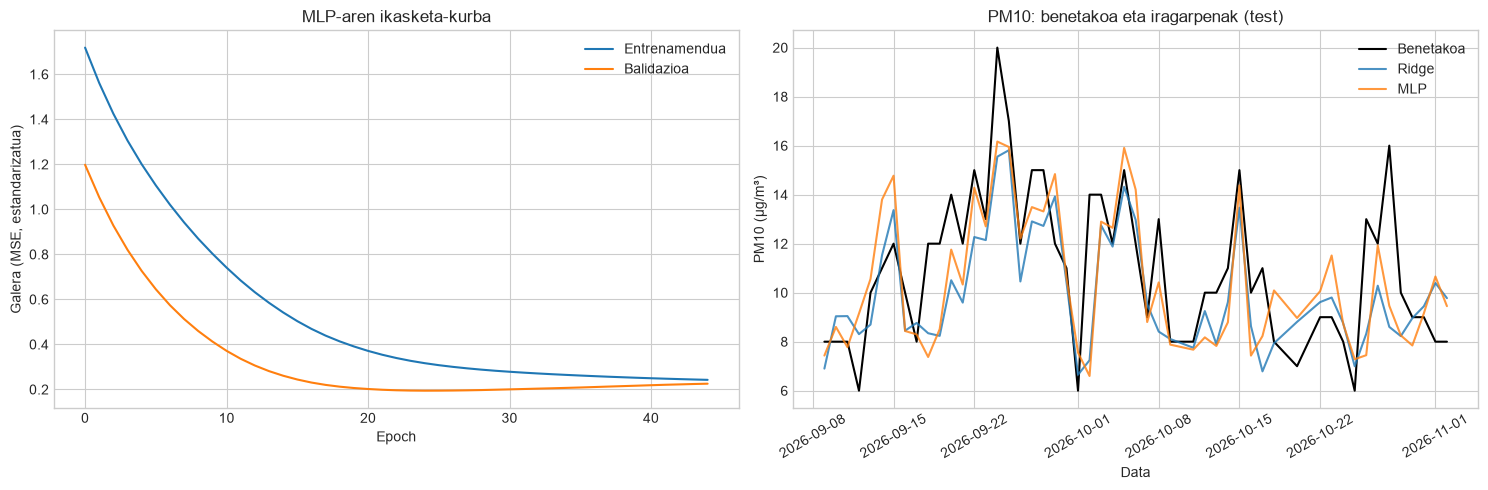

In [4]:
hazi_emaitzak, paketeak = [], {}
for hazia in [42, 1, 2, 3, 4]:
    paketeak[hazia] = entrenatu_mlp(X_tr, y_tr, **onena, hazia=hazia)
    pred = iragarri_mlp(*paketeak[hazia][:4], X_te)
    hazi_emaitzak.append({'Hazia': hazia, **metrikak(y_te, pred), 'Epoch-ak': len(paketeak[hazia][4].history['loss'])})
hazi_emaitzak = pd.DataFrame(hazi_emaitzak).set_index('Hazia')
display(hazi_emaitzak.round(3))
print('Batezbestekoa:', hazi_emaitzak[['MAE', 'RMSE', 'R²']].mean().round(3).to_dict())
print('Desbideratzea:', hazi_emaitzak[['MAE', 'RMSE', 'R²']].std().round(3).to_dict())

# 42 hazia erabiltzen dugu eredu gisa
aurre_mlp, mlp, y_batez, y_desb, historia = paketeak[42]
mlp.summary()
pred_mlp = iragarri_mlp(aurre_mlp, mlp, y_batez, y_desb, X_te)
pred_ridge = ridge.predict(X_te)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(15, 5))
a1.plot(historia.history['loss'], label='Entrenamendua')
a1.plot(historia.history['val_loss'], label='Balidazioa')
a1.set_title('MLP-aren ikasketa-kurba')
a1.set_xlabel('Epoch')
a1.set_ylabel('Galera (MSE, estandarizatua)')
a1.legend()
datak = df_eredua['Date'].iloc[muga:]
a2.plot(datak, y_te, label='Benetakoa', color='black')
a2.plot(datak, pred_ridge, label='Ridge', alpha=0.8)
a2.plot(datak, pred_mlp, label='MLP', alpha=0.8)
a2.set_title('PM10: benetakoa eta iragarpenak (test)')
a2.set_xlabel('Data')
a2.set_ylabel('PM10 (µg/m³)')
a2.tick_params(axis='x', rotation=30)
a2.legend()
plt.tight_layout()
plt.show()

## 5. Konparazioa eredu klasikoekin

In [5]:
baseline = np.full(len(y_te), y_tr.mean())
konparazioa = pd.DataFrame({
    'Batezbestekoa': {'Balidazio RMSE': np.nan, **metrikak(y_te, baseline)},
    'Ridge': {'Balidazio RMSE': ridge_bal_rmse, **metrikak(y_te, pred_ridge)},
    'MLP (42 hazia)': {'Balidazio RMSE': mlp_bal_rmse, **metrikak(y_te, pred_mlp)},
    'MLP (5 haziren batezbestekoa)': {'Balidazio RMSE': mlp_bal_rmse, **hazi_emaitzak[['MAE', 'RMSE', 'R²']].mean()},
}).T.round(3)
display(konparazioa)

eredu_onena = 'Ridge' if ridge_bal_rmse <= mlp_bal_rmse else 'MLP'
print('Eredu onena (balidazioa):', eredu_onena)

,Balidazio RMSE,MAE,RMSE,R²
Batezbestekoa,NaN,2.643,3.230,-0.137
Ridge,2.729,1.817,2.415,0.364
MLP (42 hazia),3.332,1.832,2.418,0.362
MLP (5 haziren batezbestekoa),3.332,2.130,2.715,0.156


Eredu onena (balidazioa): Ridge


**Emaitzen irakurketa:**

- **Ridge da onena balidazioan** (RMSE ≈ 2,73, MLP-ak ≈ 3,33), eta horrexegatik aukeratzen dugu.
- **Test multzoan, 42 haziarekin, ia berdinduta daude** (R² ≈ 0,36 biak), baina emaitza hori ez da ohikoa: 5 haziren batezbestekoa R² ≈ 0,16 da.
- **MLP-a ez da egonkorra:** haziaren arabera, R²-a -0,64 eta 0,50 artean dago. Ridge-k, aldiz, beti emaitza bera ematen du.
- **Biak batezbestekoa iragartzea baino hobeak dira** (R² ≈ -0,14), baina MLP-ak ez dio Ridge-ri ezer gehitzen datu kopuru honekin. Bi ereduek ere ezin dute urriko eta azaroko datuetatik ikasi, entrenamenduan ez baitaude.

## 6. Esportazioa Jetson Nano-rako

Jetson Nano-k Python zaharra izan dezake, eta `.pkl` fitxategiek scikit-learn bertsio berbera behar dute. Horregatik, aurreprozesamendua eta eredua **formatu independenteetan** gordetzen ditugu:

- `aurreprozesamendua.json`: medianak, batezbestekoak, desbideratzeak eta kategoriak.
- `ridge_eredua.json`: Ridge-ren koefizienteak (NumPy-rekin bakarrik exekutatzen da).
- `mlp_pm10.keras` eta `mlp_pm10.tflite`: sare neuronala.

Azkenik, esportatutako fitxategiek jatorrizko ereduen emaitza berberak ematen dituztela egiaztatzen dugu.

In [6]:
# 1. Aurreprozesamendua JSON-era (entrenamendu-multzo osoarekin doitua)
aurre = ridge.named_steps['aurre']
imputer = aurre.named_transformers_['zenbakizkoak'].named_steps['imputer']
scaler = aurre.named_transformers_['zenbakizkoak'].named_steps['scaler']
onehot = aurre.named_transformers_['kategorikoak']
parametroak = {
    'zenbakizkoak': zenbakizkoak,
    'kategorikoak': kategorikoak,
    'medianak': imputer.statistics_.tolist(),
    'batezbestekoak': scaler.mean_.tolist(),
    'desbideratzeak': scaler.scale_.tolist(),
    'kategoriak': [c.astype(int).tolist() for c in onehot.categories_],
    'pm10_batezbestekoa': y_batez,
    'pm10_desbideratzea': y_desb,
}
json.dump(parametroak, open('aurreprozesamendua.json', 'w', encoding='utf-8'), ensure_ascii=False, indent=1)

# 2. Ridge JSON-era
json.dump({'koefizienteak': ridge.named_steps['eredua'].coef_.tolist(),
           'konstantea': float(ridge.named_steps['eredua'].intercept_)},
          open('ridge_eredua.json', 'w', encoding='utf-8'), indent=1)

# 3. MLP Keras eta TFLite formatuetan
mlp.save('mlp_pm10.keras')
mlp.export('mlp_saved_model', verbose=False)
tflite_eredua = tf.lite.TFLiteConverter.from_saved_model('mlp_saved_model').convert()
open('mlp_pm10.tflite', 'wb').write(tflite_eredua)
shutil.rmtree('mlp_saved_model')

# 4. Egiaztapena: scikit-learn gabeko aurreprozesamendua (Jetson-en erabiliko dena)
def aurreprozesatu(lerroak, p):
    balioak = lerroak[p['zenbakizkoak']].to_numpy(dtype='float64')
    balioak = np.where(np.isnan(balioak), p['medianak'], balioak)
    zenb = (balioak - np.array(p['batezbestekoak'])) / np.array(p['desbideratzeak'])
    kat = [np.stack([(lerroak[z].to_numpy() == k).astype('float64') for k in kategoriak], axis=1)
           for z, kategoriak in zip(p['kategorikoak'], p['kategoriak'])]
    return np.hstack([zenb] + kat)

p = json.load(open('aurreprozesamendua.json', encoding='utf-8'))
r = json.load(open('ridge_eredua.json', encoding='utf-8'))
X_jetson = aurreprozesatu(X_te, p)
pred_ridge_json = X_jetson @ np.array(r['koefizienteak']) + r['konstantea']

interpretea = tf.lite.Interpreter(model_path='mlp_pm10.tflite')
interpretea.allocate_tensors()
sarrera, irteera = interpretea.get_input_details()[0], interpretea.get_output_details()[0]
pred_tflite = []
for lerroa in X_jetson.astype('float32'):
    interpretea.set_tensor(sarrera['index'], lerroa[None, :])
    interpretea.invoke()
    pred_tflite.append(interpretea.get_tensor(irteera['index']).item() * p['pm10_desbideratzea'] + p['pm10_batezbestekoa'])

print(f"Ridge JSON vs scikit-learn, alde handiena: {np.abs(pred_ridge_json - pred_ridge).max():.6f} µg/m³")
print(f"MLP TFLite vs Keras, alde handiena: {np.abs(np.array(pred_tflite) - pred_mlp).max():.6f} µg/m³")
print('Tamainak (KB):', {f: round(os.path.getsize(f) / 1024, 1) for f in
                         ['aurreprozesamendua.json', 'ridge_eredua.json', 'mlp_pm10.keras', 'mlp_pm10.tflite']})

Ridge JSON vs scikit-learn, alde handiena: 0.000000 µg/m³
MLP TFLite vs Keras, alde handiena: 0.000001 µg/m³
Tamainak (KB): {'aurreprozesamendua.json': 0.7, 'ridge_eredua.json': 0.6, 'mlp_pm10.keras': 22.7, 'mlp_pm10.tflite': 2.3}


Bi egiaztapenek alde arbuiagarria erakusten dute (≈ 0,000001 µg/m³ edo gutxiago). Beraz, esportatutako fitxategiak jatorrizko ereduen baliokideak dira.

## 7. Ondorioak

**Jetson Nano-ra eramateko eredua: Ridge.**

1. **Balidazioan hobea da** MLP-a baino (RMSE ≈ 2,73 vs 3,33), eta *test*-ean ez du okerrago egiten.
2. **Egonkorra eta interpretagarria da:** emaitza ez dago hasierako ausazko pisuen mende, eta koefizienteak azter daitezke.
3. **Oso arina da:** NumPy-rekin bakarrik exekutatzen da, 0,6 KB-eko fitxategi batekin, eta ez du TensorFlow behar.

**Zergatik ez du sare neuronalak irabazi?** MLP-ek datu asko behar izaten dituzte erlazio konplexuak ikasteko, eta hemen 205 entrenamendu-errenkada eta urte bakarreko datuak ditugu. Datu gutxirekin, eredu sinple eta erregularizatu batek emaitza hobeak eta egonkorragoak ematen ditu.

**Mugak:**

- R² ≈ 0,36 apala da, eta eredu hau egun bereko PM10-a kalkulatzeko da, ez biharkoa iragartzeko (ikus SAA zatiko 3.1. atala).
- Hiperparametroen bilaketa txikia izan da (6 konfigurazio), datu gutxi daudelako.
- Exekuzio-denborak oraindik ez dira neurtu: Jetson Nano-n bertan neurtu behar dira.

## 8. Iturriak

- Datuak: [Open Data Euskadi](https://opendata.euskadi.eus), Euskadiko airearen kalitatearen sarea (Mundaka estazioa).
- [Keras dokumentazioa](https://keras.io/api/) eta [TensorFlow Lite](https://www.tensorflow.org/lite).
- [scikit-learn dokumentazioa](https://scikit-learn.org/stable/): `Pipeline`, `TimeSeriesSplit`, `GridSearchCV`.